In [1]:
import numpy as np
from hcipy import *
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import sys
import os

sys.path.append(os.path.abspath(os.path.join(os.path.dirname('adc_sims'), '..')))

from adcFitter_onsky import AdcFitter

In [38]:
#system params
wavelength = 908E-9
bw = 120E-9
grating_angle = 28
grating_freq = 47

ADC = AdcFitter(wavelength=wavelength,grating_freq=grating_freq,grating_angle=grating_angle) 

In [48]:
#fitting functions
from scipy.optimize import curve_fit

def gauss(x,mu,sigma2):
    return np.exp(-(x-mu)**2 / (2 * sigma2) )

def isolate_gaussian(data):
    new_data = data.copy()

    mid = np.argmax(new_data)
    first_derivative = np.gradient(new_data) 

    valley_indices = np.where((first_derivative[:-1] < 0) & (first_derivative[1:] > 0))[0] + 1

    left_valley = valley_indices[valley_indices < mid][-1] if any(valley_indices < mid) else None
    right_valley = valley_indices[valley_indices > mid][0] if any(valley_indices > mid) else None

    if left_valley is not None:
        new_data[0:left_valley] = 0
        #right_valley -= left_valley

    if right_valley is not None:
        new_data[right_valley:len(new_data)] = 0
        #print(right_valley)

    return new_data


def mu(data):
    isolated = isolate_gaussian(data)
    x = np.arange(len(data))
    popt = curve_fit(gauss,x,isolated,p0=[np.argmax(data),2])

    mu = popt[0][0]
    sigma = popt[0][1]
    fwhm = 2 * np.sqrt(2 * np.log(2)) * np.sqrt(sigma)
    return mu, sigma, fwhm
    

(262144,)

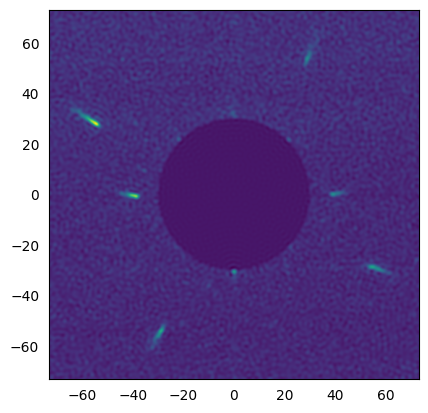

In [49]:
img = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/2025B/zband/z_sparkles_counter_unsat.fits')[0]
img = ADC.filter_image(ADC.crop_image(img,extent=512))


#img = img_cube[3]
fig, ax = plt.subplots()
imshow_field(img)
ax.tick_params(left=False,right=False,bottom=False)
img.shape

In [50]:
print(ADC.normalized_wavelength)

1.3841463414634145


[  0.         -65.05487805]


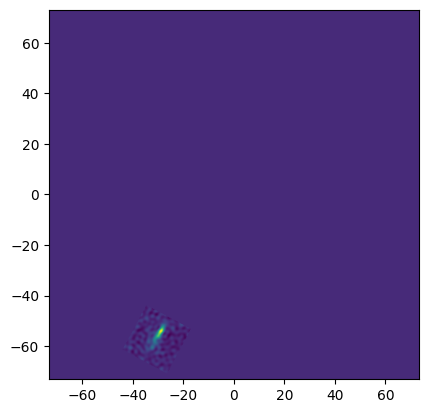

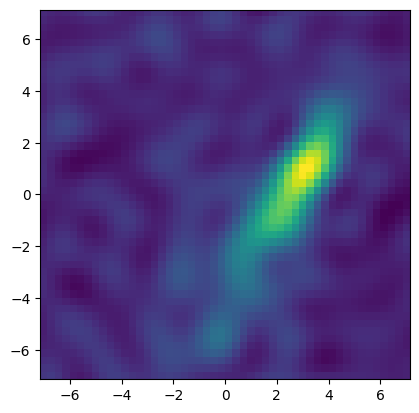

In [55]:
#cut out the speckle window
speckle_number = 2

#locate the general area of the speckle
extent=20
speckle_coords = np.array([[0, ADC.grating_freq * ADC.normalized_wavelength],[ADC.grating_freq * ADC.normalized_wavelength,0],[0, -ADC.grating_freq * ADC.normalized_wavelength],[-ADC.grating_freq * ADC.normalized_wavelength,0]])
speckle_center = speckle_coords[speckle_number]
print(speckle_center)

#cut out the speckle area
rect = make_rotated_aperture(make_rectangular_aperture(size=(extent,extent), center=speckle_coords[speckle_number]), np.deg2rad(-grating_angle))(img.grid)
speckle_img = rect * img

#find the center of intensity of the speckle area and window the image around that center
center_of_intensity = np.array([sum(speckle_img*speckle_img.grid.x)/sum(speckle_img),sum(speckle_img*speckle_img.grid.y)/sum(speckle_img)])
window_size=50
new_img = ADC.window_field(img,[center_of_intensity[0],center_of_intensity[1]],window_size,window_size)

#tada!
imshow_field(speckle_img)
plt.figure()
imshow_field(new_img)

In [56]:
#now iterate through all the slices
shaped = new_img.shaped
mus = np.zeros(shaped.shape[0])
zscores = np.zeros(shaped.shape[0])
maxes = np.zeros(shaped.shape[0])

snr_threshold = 2


for i in range(shaped.shape[0]): #in np.array([40,0]):
    if speckle_number % 2 != 0: #columns vs rows depending on which speckle it is
        sliced = shaped[:,i]
    else: sliced = shaped[i,:]

    zscore = (np.max(sliced) - np.mean(sliced))/np.std(sliced)
    zscores[i] = zscore

    if zscore > snr_threshold:
        s = isolate_gaussian(sliced)
        s /= s.max()
        m, std, fwhm = mu(s)
        mus[i] = m
    else: mus[i] = -1


Text(0, 0.5, 'row index of mean position')

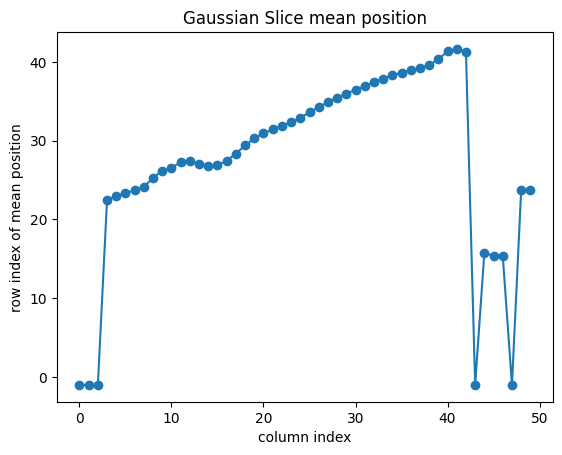

In [57]:
#plot the means
plt.plot(mus,'-o')
plt.title('Gaussian Slice mean position')
plt.xlabel('column index')
plt.ylabel('row index of mean position')

[ 1  2  3  4 15 40 41 42 43 44 45 46 47 48 49]
slope: 0.55
corresponding angle: 0.50 (rad) or 28.63°


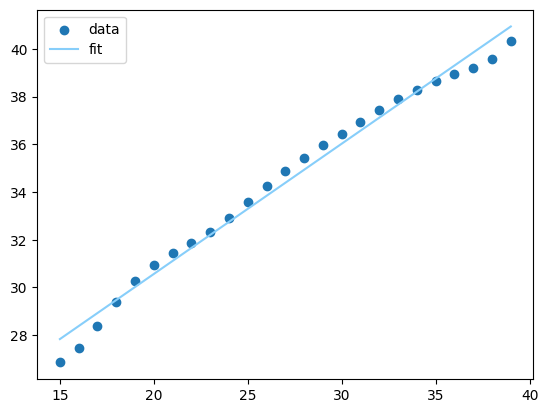

In [58]:
#plot the linear region
deriv2 = np.gradient(np.gradient(mus))

deriv2_cutoff = 0.4

nonlin_region = np.squeeze(np.where(np.abs(deriv2) > deriv2_cutoff))
print(nonlin_region)

midpoint = 20
leftbound = nonlin_region[nonlin_region < midpoint][-1]
rightbound = nonlin_region[nonlin_region > midpoint][0]


linear_region = mus[leftbound:rightbound]
lin_x = np.arange(len(linear_region)) + leftbound

m , b = np.polyfit(lin_x,linear_region,deg=1)
angle = np.arctan(m)
print(f'slope: {m:.2f}\ncorresponding angle: {angle:.2f} (rad) or {np.degrees(angle):.2f}°')
plt.scatter(lin_x,linear_region,label='data')
plt.plot(lin_x, m * lin_x + b,label='fit',color='LightSkyBlue')
plt.legend()
plt.show()

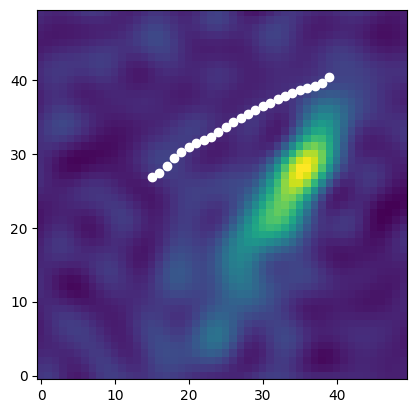

In [59]:
plt.imshow(new_img.shaped,origin='lower')
#imshow_field(new_img)
plt.plot(lin_x ,mus[leftbound:rightbound],'o',color='White')
#plt.plot(lin_x, m * lin_x + b,'--',label='fit',color='black')

In [10]:
#ok let's try this again idk what changed
def slice_speckle_angle(img,speckle_number,print_updates=False):
    #locate the general area of the speckle
    extent=20
    speckle_coords = np.array([[0, ADC.grating_freq * ADC.normalized_wavelength],[ADC.grating_freq * ADC.normalized_wavelength,0],[0, -ADC.grating_freq * ADC.normalized_wavelength],[-ADC.grating_freq * ADC.normalized_wavelength,0]])
    speckle_center = speckle_coords[speckle_number]
    #print(speckle_center)

    #cut out the speckle area
    rect = make_rotated_aperture(make_rectangular_aperture(size=(extent,extent), center=speckle_coords[speckle_number]), np.deg2rad(-grating_angle))(img.grid)
    speckle_img = rect * img

    #find the center of intensity of the speckle area and window the image around that center
    center_of_intensity = np.array([sum(speckle_img*speckle_img.grid.x)/sum(speckle_img),sum(speckle_img*speckle_img.grid.y)/sum(speckle_img)])
    window_size=50
    new_img = ADC.window_field(img,[center_of_intensity[0],center_of_intensity[1]],window_size,window_size)
    
    shaped = new_img.shaped
    mus = np.zeros(shaped.shape[0])

    snr_threshold = 2

    for i in range(shaped.shape[0]): #in np.array([40,0]):
        if speckle_number % 2 != 0: #columns vs rows depending on which speckle it is
            sliced = shaped[:,i]
        else: sliced = shaped[i,:]

        zscore = (np.max(sliced) - np.mean(sliced))/np.std(sliced)

        if zscore > snr_threshold:
            s = isolate_gaussian(sliced)
            s /= s.max()
            m, std, fwhm = mu(s)
            mus[i] = m
        else: mus[i] = -1

    deriv2 = np.gradient(np.gradient(mus))

    nonlin_region = np.squeeze(np.where(np.abs(deriv2) > 0.4))
    #print(nonlin_region)

    midpoint = 20
    leftbound = nonlin_region[nonlin_region < midpoint][-1] if any(nonlin_region < midpoint) else None
    rightbound = nonlin_region[nonlin_region > midpoint][0] if any(nonlin_region > midpoint) else None

    if leftbound is not None and rightbound is not None:
        linear_region = mus[leftbound:rightbound]
        lin_x = np.arange(len(linear_region))

        m , b = np.polyfit(lin_x,linear_region,deg=1)
        angle = np.arctan(m)
        if print_updates ==True:
            print(f'slope: {m:.2f}\ncorresponding angle: {angle:.2f} (rad) or {np.degrees(angle):.2f}°')

        return np.degrees(angle)
    else: 
        if print_updates == True:
            print(f'unable to fit speckle {speckle_number}')
        return np.nan


In [11]:
#now find the speckle angles for all four 
def all_speckle_angles(img):
    angles = np.zeros(4)
    for i in range(4):
        #print(i)
        angles[i] = slice_speckle_angle(img,i)
    return angles

In [19]:
fieldcube = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/2025B/i_sparkles_counter_unsat.fits')
img_cube = []

for i, field in enumerate(fieldcube):
    filtered = ADC.filter_image(ADC.crop_image(field,mask_diam=60)) 
    #filtered = Field(np.array([x if x > 0 else 0 for x in filtered ]),filtered.grid)
    img_cube.append(filtered)

In [20]:
all_angles = np.zeros(shape=(len(img_cube),4))

for i,img in enumerate(img_cube):
    a = all_speckle_angles(img)
    all_angles[i,0:4] = a

/var/folders/lz/tstdmcf92cv45_pgvnk0mkgr0000gn/T/ipykernel_51964/3528794934.py:5: RuntimeWarning: overflow encountered in exp
  return np.exp(-(x-mu)**2 / (2 * sigma2) )


In [21]:
print(all_angles.shape)

(51, 4)


3.0513051840216003
6.1291429976750695
2.8418214793976238
5.721288071337677


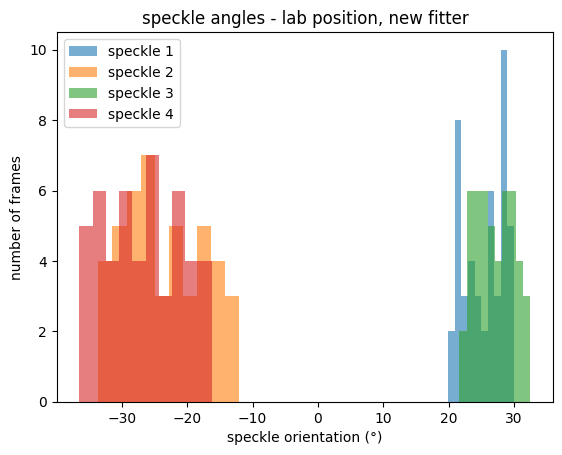

In [22]:
for i in range(4):
    plt.hist(all_angles[:,i],label=f'speckle {i+1}',alpha=0.6)
    print(np.nanstd(all_angles[:,i]))

plt.title('speckle angles - lab position, new fitter')
plt.xlabel('speckle orientation (°)')
plt.ylabel('number of frames')
plt.legend()

In [23]:
all_angles.shape

(51, 4)

speckles 1&3 stdev: 5.695124152814679
speckles 2&4 stdev: 11.549222833149775


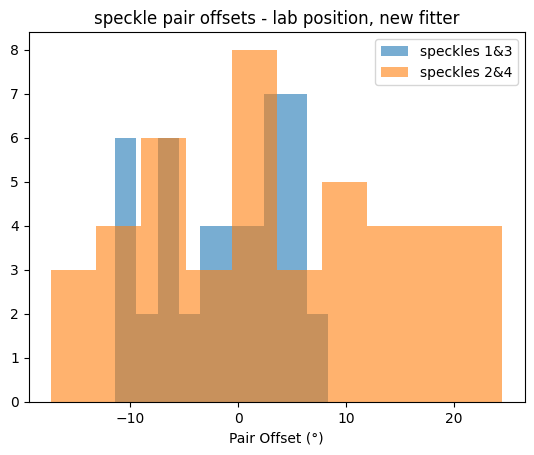

In [24]:
#and the same plot but with the speckle differences, because that's what you're using to control
speckles13 = all_angles[:,0] - all_angles[:,2]
speckles24 = all_angles[:,1] - all_angles[:,3]

print(f'speckles 1&3 stdev: {np.nanstd(speckles13)}')
print(f'speckles 2&4 stdev: {np.nanstd(speckles24)}')

plt.hist(speckles13,alpha=0.6,label='speckles 1&3')
plt.hist(speckles24,alpha=0.6,label='speckles 2&4')
plt.title('speckle pair offsets - lab position, new fitter')
plt.xlabel('Pair Offset (°)')
plt.legend()
plt.show()